<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Box Plots**


Estimated time needed: **45** minutes


In this lab, you will focus on the visualization of data. The dataset will be provided through an RDBMS, and you will need to use SQL queries to extract the required data.


## Objectives


In this lab you will perform the following:


-   Visualize the distribution of data.

-   Visualize the relationship between two features.

-   Visualize data composition and comparisons using box plots.


### Setup: Connecting to the Database


#### 1. Download the Database File


In [1]:
# The original `!wget` magic command only runs in Jupyter/Linux environments.
# It is kept below as a comment. Use urllib instead so it works in plain VS Code.
# !wget https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/QR9YeprUYhOoLafzlLspAw/survey-results-public.sqlite
import os
import urllib.request
import urllib.error

sqlite_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/QR9YeprUYhOoLafzlLspAw/survey-results-public.sqlite'
sqlite_file = 'survey-results-public.sqlite'
if not (os.path.exists(sqlite_file) and os.path.getsize(sqlite_file) > 0):
    print('Downloading survey-results-public.sqlite (this may take a while)...')
    urllib.request.urlretrieve(sqlite_url, sqlite_file)
print('SQLite DB ready at:', os.path.abspath(sqlite_file))

SQLite DB ready at: c:\Users\Jerome\github-jtgreta\ibm-data-analyst\09-ibm-data-analyst-capstone-project\survey-results-public.sqlite


#### 2. Connect to the Database


**Install the needed libraries**


In [2]:
# The original `!pip install` magic commands only run in Jupyter environments.
# They are kept below as comments. Use subprocess instead so the packages are
# installed with the same Python interpreter that is selected in VS Code.
# !pip install pandas
import importlib.util
import subprocess
import sys

def install(package, import_name=None):
    """Quietly pip-install a package if it is not already available."""
    import_name = import_name or package
    try:
        spec = importlib.util.find_spec(import_name)
    except (ImportError, ModuleNotFoundError, ValueError):
        spec = None
    if spec is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', package])

install('pandas', 'pandas')
install('matplotlib', 'matplotlib')

In [3]:
# The original `!pip install matplotlib` magic command only runs in Jupyter
# environments. It is kept below as a comment; matplotlib is installed by
# the installer in the cell above so it also works in plain VS Code.
# !pip install matplotlib

In [4]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

# Connect to the SQLite database
conn = sqlite3.connect('survey-results-public.sqlite')


## Demo: Basic SQL Queries


#### Demo 1: Count the Number of Rows in the Table


In [5]:
QUERY = "SELECT COUNT(*) FROM main"
# df = pd.read_sql_query(QUERY, conn)   # original (overwrote df)
count_df = pd.read_sql_query(QUERY, conn)
print(count_df)

   COUNT(*)
0     65437


#### Demo 2: List All Tables


In [6]:
QUERY = """
SELECT name as Table_Name 
FROM sqlite_master 
WHERE type = 'table'
"""
pd.read_sql_query(QUERY, conn)


,Table_Name
0,main


#### Demo 3: Group Data by Age


In [7]:
QUERY = """
SELECT Age, COUNT(*) as count 
FROM main 
GROUP BY Age 
ORDER BY Age
"""
df_age = pd.read_sql_query(QUERY, conn)
print(df_age)


                  Age  count
0     18-24 years old  14098
1     25-34 years old  23911
2     35-44 years old  14942
3     45-54 years old   6249
4     55-64 years old   2575
5   65 years or older    772
6   Prefer not to say    322
7  Under 18 years old   2568


## Visualizing Data


### Task 1: Visualizing the Distribution of Data


**1. Box Plot of `CompTotal` (Total Compensation)**


Use a box plot to analyze the distribution and outliers in total compensation.


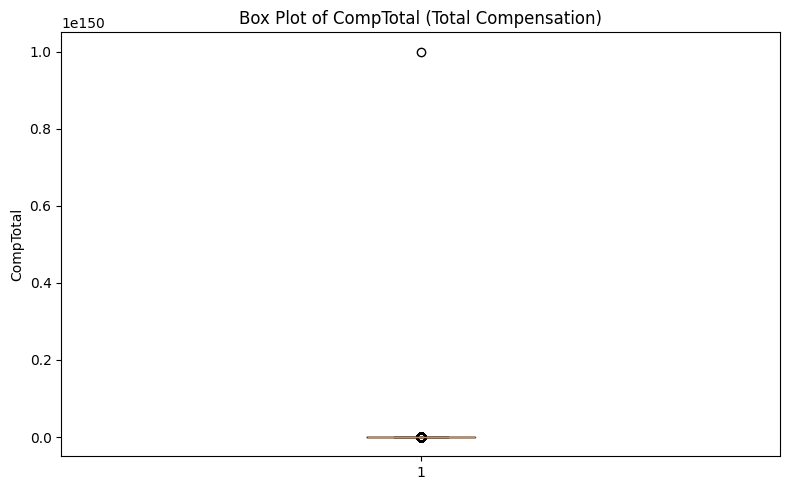

In [8]:
# your code goes here
# 1. Box Plot of CompTotal (Total Compensation)
QUERY = "SELECT CompTotal FROM main WHERE CompTotal IS NOT NULL"
comp_df = pd.read_sql_query(QUERY, conn)

plt.figure(figsize=(8, 5))
plt.boxplot(comp_df['CompTotal'].dropna(), vert=True)
plt.title('Box Plot of CompTotal (Total Compensation)')
plt.ylabel('CompTotal')
plt.tight_layout()
plt.show()

**2. Box Plot of Age (converted to numeric values)**


Convert the `Age` column into numerical values and visualize the distribution.


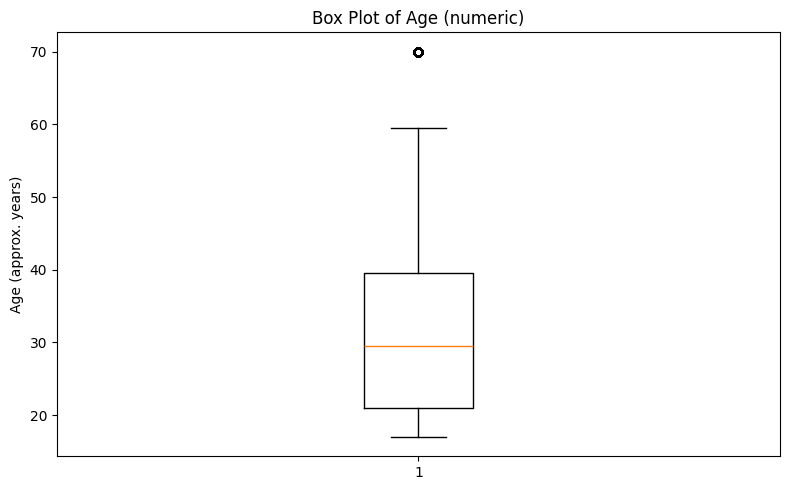

In [9]:
# your code goes here
# 2. Box Plot of Age (converted to numeric values)
age_mid = {
    'Under 18 years old': 17,
    '18-24 years old': 21,
    '25-34 years old': 29.5,
    '35-44 years old': 39.5,
    '45-54 years old': 49.5,
    '55-64 years old': 59.5,
    '65 years or older': 70,
}
QUERY = "SELECT Age FROM main"
age_df = pd.read_sql_query(QUERY, conn)
age_df['AgeNum'] = age_df['Age'].map(age_mid)

plt.figure(figsize=(8, 5))
plt.boxplot(age_df['AgeNum'].dropna(), vert=True)
plt.title('Box Plot of Age (numeric)')
plt.ylabel('Age (approx. years)')
plt.tight_layout()
plt.show()

### Task 2: Visualizing Relationships in Data


**1. Box Plot of `CompTotal` Grouped by Age Groups:**


Visualize the distribution of compensation across different age groups.


<Figure size 1200x600 with 0 Axes>

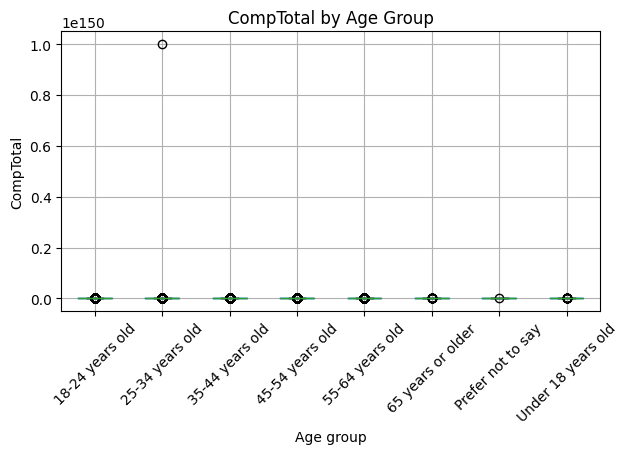

In [10]:
# your code goes here
# 1. Box Plot of CompTotal Grouped by Age Groups
QUERY = "SELECT Age, CompTotal FROM main WHERE CompTotal IS NOT NULL"
age_comp_df = pd.read_sql_query(QUERY, conn)

plt.figure(figsize=(12, 6))
age_comp_df.boxplot(column='CompTotal', by='Age', rot=45)
plt.title('CompTotal by Age Group')
plt.suptitle('')
plt.xlabel('Age group')
plt.ylabel('CompTotal')
plt.tight_layout()
plt.show()

**2. Box Plot of `CompTotal` Grouped by Job Satisfaction (`JobSatPoints_6`):**


Examine how compensation varies based on job satisfaction levels.


<Figure size 1200x600 with 0 Axes>

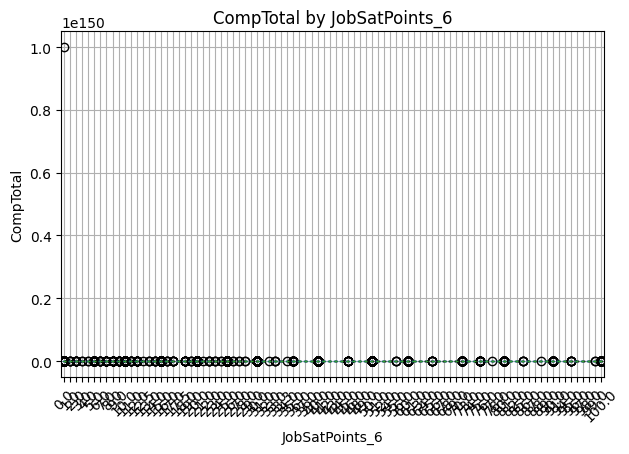

In [11]:
# your code goes here
# 2. Box Plot of CompTotal Grouped by JobSatPoints_6
QUERY = "SELECT JobSatPoints_6, CompTotal FROM main WHERE CompTotal IS NOT NULL AND JobSatPoints_6 IS NOT NULL"
js_comp_df = pd.read_sql_query(QUERY, conn)

plt.figure(figsize=(12, 6))
js_comp_df.boxplot(column='CompTotal', by='JobSatPoints_6', rot=45)
plt.title('CompTotal by JobSatPoints_6')
plt.suptitle('')
plt.xlabel('JobSatPoints_6')
plt.ylabel('CompTotal')
plt.tight_layout()
plt.show()

### Task 3: Visualizing the Composition of Data


**1. Box Plot of `ConvertedCompYearly` for the Top 5 Developer Types:**


Analyze compensation across the top 5 developer roles.


<Figure size 1200x600 with 0 Axes>

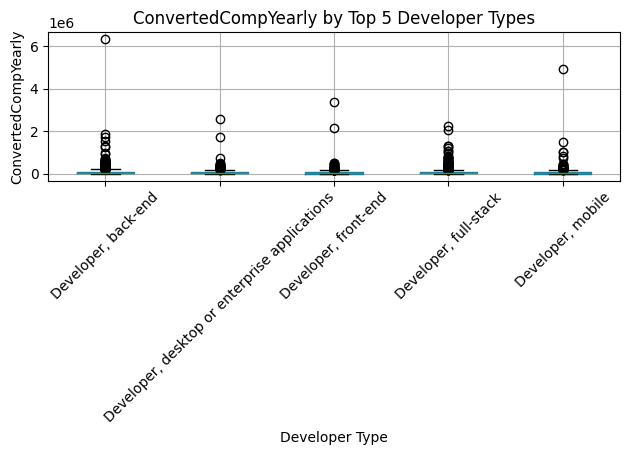

In [12]:
# your code goes here
# 1. Box Plot of ConvertedCompYearly for the Top 5 Developer Types
QUERY = "SELECT DevType, ConvertedCompYearly FROM main WHERE DevType IS NOT NULL AND ConvertedCompYearly IS NOT NULL"
dev_comp_df = pd.read_sql_query(QUERY, conn)

# DevType can contain multiple values separated by ';'; take the first one
dev_comp_df['DevType'] = dev_comp_df['DevType'].str.split(';').str[0]
top5_devs = dev_comp_df['DevType'].value_counts().head(5).index.tolist()
filtered = dev_comp_df[dev_comp_df['DevType'].isin(top5_devs)]

plt.figure(figsize=(12, 6))
filtered.boxplot(column='ConvertedCompYearly', by='DevType', rot=45)
plt.title('ConvertedCompYearly by Top 5 Developer Types')
plt.suptitle('')
plt.xlabel('Developer Type')
plt.ylabel('ConvertedCompYearly')
plt.tight_layout()
plt.show()

**2. Box Plot of `CompTotal` for the Top 5 Countries:**


Analyze compensation across respondents from the top 5 countries.


<Figure size 1200x600 with 0 Axes>

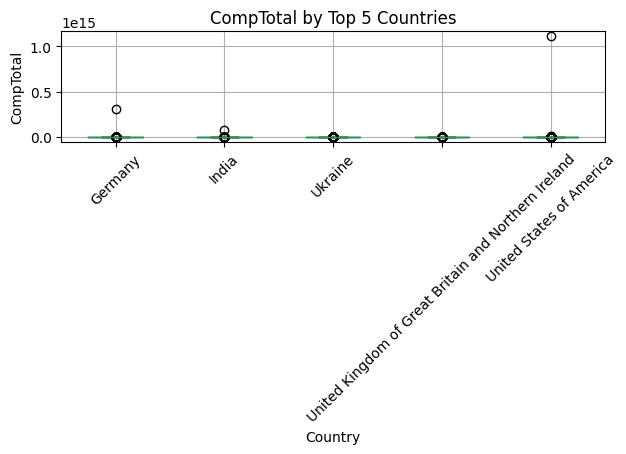

In [13]:
# your code goes here
# 2. Box Plot of CompTotal for the Top 5 Countries
QUERY = "SELECT Country, CompTotal FROM main WHERE Country IS NOT NULL AND CompTotal IS NOT NULL"
country_comp_df = pd.read_sql_query(QUERY, conn)

top5_countries = country_comp_df['Country'].value_counts().head(5).index.tolist()
filtered = country_comp_df[country_comp_df['Country'].isin(top5_countries)]

plt.figure(figsize=(12, 6))
filtered.boxplot(column='CompTotal', by='Country', rot=45)
plt.title('CompTotal by Top 5 Countries')
plt.suptitle('')
plt.xlabel('Country')
plt.ylabel('CompTotal')
plt.tight_layout()
plt.show()

### Task 4: Visualizing Comparison of Data


**1. Box Plot of CompTotal Across Employment Types:**


Analyze compensation for different employment types.


C:\Users\Jerome\AppData\Local\Temp\ipykernel_22052\2072153429.py:12: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


<Figure size 1200x600 with 0 Axes>

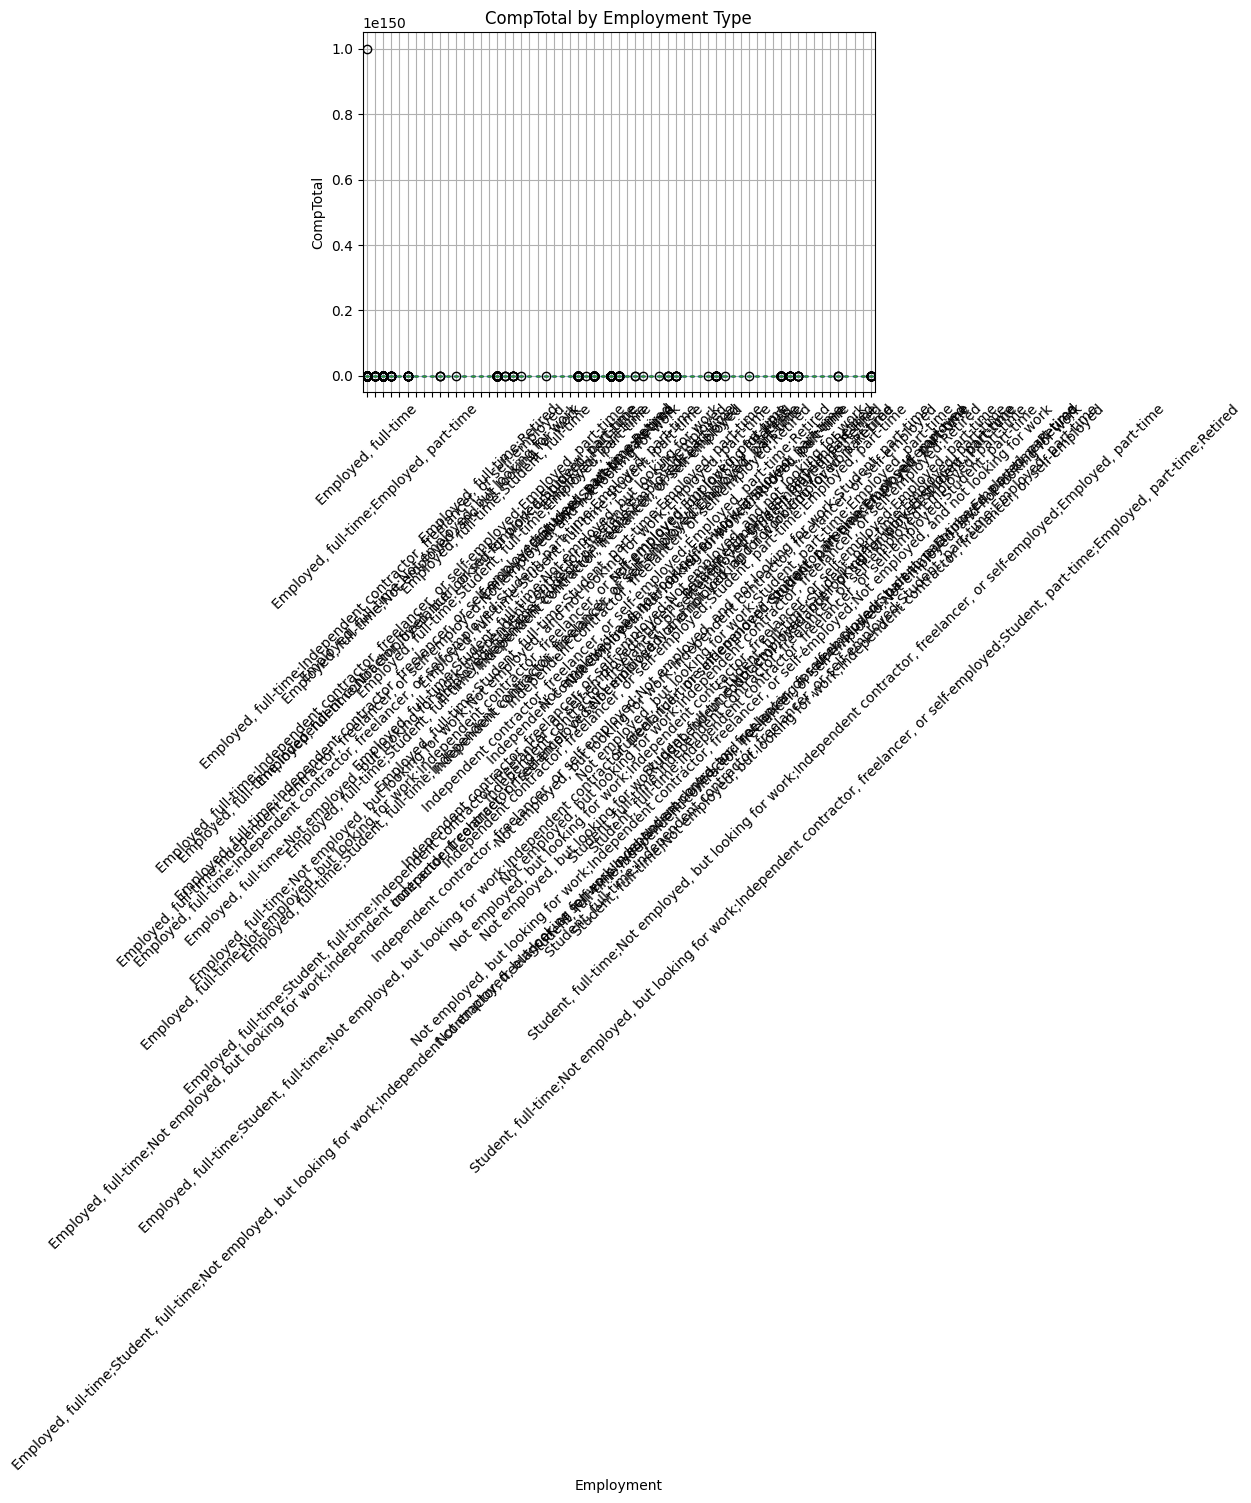

In [14]:
# your code goes here
# 1. Box Plot of CompTotal Across Employment Types
QUERY = "SELECT Employment, CompTotal FROM main WHERE Employment IS NOT NULL AND CompTotal IS NOT NULL"
emp_comp_df = pd.read_sql_query(QUERY, conn)

plt.figure(figsize=(12, 6))
emp_comp_df.boxplot(column='CompTotal', by='Employment', rot=45)
plt.title('CompTotal by Employment Type')
plt.suptitle('')
plt.xlabel('Employment')
plt.ylabel('CompTotal')
plt.tight_layout()
plt.show()

**2. Box Plot of `YearsCodePro` by Job Satisfaction (`JobSatPoints_6`):**


Examine the distribution of professional coding years by job satisfaction levels.


<Figure size 1200x600 with 0 Axes>

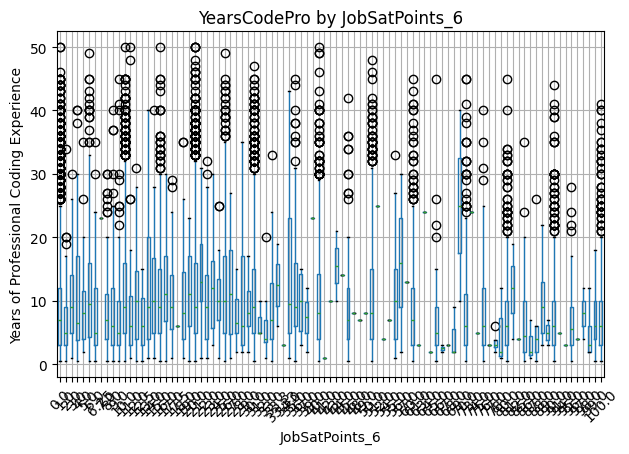

In [15]:
# your code goes here
# 2. Box Plot of YearsCodePro by JobSatPoints_6
QUERY = "SELECT JobSatPoints_6, YearsCodePro FROM main WHERE JobSatPoints_6 IS NOT NULL AND YearsCodePro IS NOT NULL"
js_ycp_df = pd.read_sql_query(QUERY, conn)

def to_years(val):
    if val == 'Less than 1 year':
        return 0.5
    if val == 'More than 50 years':
        return 50
    try:
        return float(val)
    except (ValueError, TypeError):
        return None

js_ycp_df['YearsCodePro_num'] = js_ycp_df['YearsCodePro'].apply(to_years)
js_ycp_df = js_ycp_df.dropna(subset=['YearsCodePro_num'])

plt.figure(figsize=(12, 6))
js_ycp_df.boxplot(column='YearsCodePro_num', by='JobSatPoints_6', rot=45)
plt.title('YearsCodePro by JobSatPoints_6')
plt.suptitle('')
plt.xlabel('JobSatPoints_6')
plt.ylabel('Years of Professional Coding Experience')
plt.tight_layout()
plt.show()

### Final Step: Close the Database Connection


After completing the lab, close the connection to the SQLite database:


In [16]:
conn.close()

## Summary


In this lab, you used box plots to visualize various aspects of the dataset, focusing on:

- Visualize distributions of compensation and age.

- Explore relationships between compensation, job satisfaction, and professional coding experience.

- Analyze data composition across developer roles and countries.

- Compare compensation across employment types and satisfaction levels.

Box plots provided clear insights into the spread, outliers, and central tendencies of various features in the dataset.


## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|               
|2024-10-07|1.2|Madhusudan Moole|Reviewed and updated lab|                                                                                      
|2024-10-06|1.0|Raghul Ramesh|Created lab|-->


Copyright © IBM Corporation. All rights reserved.
